# BQ09 — Khoảng phí định kỳ nào cần được xem xét bill/plan?

## Câu hỏi kinh doanh
`TotalRecurringCharge` có tạo ra một vùng churn đáng chú ý, đủ nhiều khách hàng và còn tồn tại khi đặt các khách hàng có `MonthlyRevenue` tương đương cạnh nhau hay không?

## Quyết định cần đưa ra
- **KEEP CANDIDATE:** chuyển khoảng phí sang BQ10 để kiểm tra price/plan mismatch và thiết kế thử nghiệm bill/plan review.
- **CONTEXT ONLY:** chỉ dùng mức phí làm bối cảnh, không tạo rule giữ chân riêng.
- **REMOVE:** không dùng phí định kỳ làm reason code nếu risk hoặc bằng chứng điều chỉnh quá yếu.

## Giới hạn diễn giải
BQ09 tìm **candidate để xem xét hóa đơn/gói cước**, không chứng minh phí gây churn và không kết luận phải giảm giá. `TotalRecurringCharge` là mức phí định kỳ trong dữ liệu, không phải toàn bộ hóa đơn hay lợi nhuận khách hàng.


In [1]:
BQ09_VERSION = 'BQ09_ANALYSIS_FIRST_RISK_REACH_V2'
print(f'Đang chạy: {BQ09_VERSION}')

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display, Markdown
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import SplineTransformer

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.style.use('seaborn-v0_8-whitegrid')

SEED = 42
N_BANDS = 5
N_KNOTS = 5
BOOTSTRAP_REPEATS = 100
STANDARDIZATION_N = 800
CURVE_POINTS = 80
MIN_CELL_N = 200
MIN_EFFECT = 0.02
MIN_REACH = 0.05
MIN_VALUE_CONSISTENCY = 0.60
MIN_DIRECTION_STABILITY = 0.80
rng = np.random.default_rng(SEED)


Đang chạy: BQ09_ANALYSIS_FIRST_RISK_REACH_V2


## 1. Khóa cohort và kiểm tra ý nghĩa dữ liệu

Giữ giá trị phí bằng 0 để audit riêng; chỉ loại churn không hợp lệ, dữ liệu thiếu và giá trị âm. Không mặc định `0` là miễn phí trước khi kiểm tra data dictionary.


In [2]:
DATA_CANDIDATES = [Path('../data/cell2cell_complete_cases.csv'), Path('data/cell2cell_complete_cases.csv')]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy data/cell2cell_complete_cases.csv')

required_columns = ['Churn', 'TotalRecurringCharge', 'MonthlyRevenue']
raw = pd.read_csv(DATA_PATH, usecols=required_columns)

def normalize_binary(series):
    values = series.astype('string').str.strip().str.lower()
    mapping = {'yes': 1, 'y': 1, 'true': 1, '1': 1, '1.0': 1,
               'no': 0, 'n': 0, 'false': 0, '0': 0, '0.0': 0}
    return values.map(mapping)

work = raw.copy()
work['Churn_bin'] = normalize_binary(work['Churn'])
work['TotalRecurringCharge'] = pd.to_numeric(work['TotalRecurringCharge'], errors='coerce')
work['MonthlyRevenue'] = pd.to_numeric(work['MonthlyRevenue'], errors='coerce')
valid_mask = (
    work[['Churn_bin', 'TotalRecurringCharge', 'MonthlyRevenue']].notna().all(axis=1)
    & work['TotalRecurringCharge'].ge(0)
    & work['MonthlyRevenue'].ge(0)
)
analysis = work.loc[valid_mask].copy()
analysis['Churn_bin'] = analysis['Churn_bin'].astype(int)

zero_mask = analysis['TotalRecurringCharge'].eq(0)
qa = pd.DataFrame({
    'Chỉ tiêu': ['Tổng đầu vào', 'Dòng bị loại', 'Cohort BQ09',
                 'Phí định kỳ bằng 0', 'Churner trong nhóm phí bằng 0',
                 'Churn rate nhóm phí bằng 0'],
    'Giá trị': [len(work), int((~valid_mask).sum()), len(analysis),
                int(zero_mask.sum()), int(analysis.loc[zero_mask, 'Churn_bin'].sum()),
                analysis.loc[zero_mask, 'Churn_bin'].mean() if zero_mask.any() else np.nan],
})
display(qa)
display(analysis[['TotalRecurringCharge', 'MonthlyRevenue']].describe(
    percentiles=[.01, .10, .50, .90, .99]).T)


,Chỉ tiêu,Giá trị
0,Tổng đầu vào,"49,752.0000"
1,Dòng bị loại,5.0000
2,Cohort BQ09,"49,747.0000"
3,Phí định kỳ bằng 0,118.0000
4,Churner trong nhóm phí bằng 0,31.0000
5,Churn rate nhóm phí bằng 0,0.2627


,count,mean,std,min,1%,10%,50%,90%,99%,max
TotalRecurringCharge,"49,747.0000",46.8401,23.7552,0.0000,10.0000,20.0000,45.0000,75.0000,120.0000,400.0000
MonthlyRevenue,"49,747.0000",58.7211,44.3163,0.0000,10.0000,26.1280,48.3800,103.3800,224.6578,"1,223.3800"


## 2. Các tỷ lệ trong BQ09 được tính như thế nào?

Với mỗi khoảng phí:

- **Churn rate** = số churner trong khoảng / số khách trong khoảng.
- **Reach** = số khách trong khoảng / tổng số khách hợp lệ của BQ09.
- **Churner coverage** = số churner trong khoảng / tổng churner của BQ09.
- **Lift** = churn rate của khoảng / churn rate toàn cohort.
- **Excess churners** = churner quan sát − số churner kỳ vọng nếu khoảng có churn rate bằng toàn cohort.

Khoảng phí được tạo theo phân vị để mỗi khoảng có quy mô đủ đọc. Đây là công cụ mô tả, không phải ngưỡng chính sách cố định.


In [3]:
analysis['ChargeBand'] = pd.qcut(analysis['TotalRecurringCharge'], q=N_BANDS, duplicates='drop')
analysis['ValueTier'] = pd.qcut(analysis['MonthlyRevenue'], q=N_BANDS, duplicates='drop')

def interval_label(interval):
    left = max(0, interval.left)
    return f'{left:,.0f}–{interval.right:,.0f}'

def wilson_interval(successes, total, z=1.96):
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - half_width, center + half_width

overall_churn = analysis['Churn_bin'].mean()
total_churners = analysis['Churn_bin'].sum()
band_summary = (
    analysis.groupby('ChargeBand', observed=True)
        .agg(Customers=('Churn_bin', 'size'),
             Churners=('Churn_bin', 'sum'),
             ChurnRate=('Churn_bin', 'mean'),
             MedianCharge=('TotalRecurringCharge', 'median'),
             MedianRevenue=('MonthlyRevenue', 'median'))
        .reset_index()
)
band_summary['ChargeRange'] = band_summary['ChargeBand'].map(interval_label).astype(str)
band_summary['Reach'] = band_summary['Customers'] / len(analysis)
band_summary['ChurnerCoverage'] = band_summary['Churners'] / total_churners
band_summary['Lift'] = band_summary['ChurnRate'] / overall_churn
band_summary['Difference_pp'] = 100 * (band_summary['ChurnRate'] - overall_churn)
band_summary['ExcessChurners'] = (
    band_summary['Churners'] - band_summary['Customers'] * overall_churn
)
intervals = [wilson_interval(int(row.Churners), int(row.Customers))
             for row in band_summary.itertuples()]
band_summary['CI_low'] = [value[0] for value in intervals]
band_summary['CI_high'] = [value[1] for value in intervals]

candidate_index = band_summary['ChurnRate'].idxmax()
reference_index = band_summary['ChurnRate'].idxmin()
candidate = band_summary.loc[candidate_index]
reference_band = band_summary.loc[reference_index]

display(band_summary[['ChargeRange', 'Customers', 'Churners', 'ChurnRate',
                      'CI_low', 'CI_high', 'Reach', 'ChurnerCoverage', 'Lift',
                      'Difference_pp', 'ExcessChurners', 'MedianRevenue']])
print(f'Churn rate toàn cohort: {overall_churn:.2%}')
print(f'Candidate mô tả ban đầu: khoảng phí {candidate["ChargeRange"]}')


,ChargeRange,Customers,Churners,ChurnRate,CI_low,CI_high,Reach,ChurnerCoverage,Lift,Difference_pp,ExcessChurners,MedianRevenue
0,0–30,13846,4602,0.3324,0.3246,0.3403,0.2783,0.3231,1.1608,4.6042,637.4911,30.2600
1,30–40,7601,2249,0.2959,0.2857,0.3062,0.1528,0.1579,1.0334,0.9553,72.6146,36.4900
2,40–49,8553,2168,0.2535,0.2444,0.2628,0.1719,0.1522,0.8853,-3.2851,-280.9704,42.2400
3,49–60,10626,3035,0.2856,0.2771,0.2943,0.2136,0.2131,0.9975,-0.0709,-7.5301,56.6050
4,60–400,9121,2190,0.2401,0.2314,0.2490,0.1833,0.1537,0.8386,-4.6224,-421.6052,86.9000


Churn rate toàn cohort: 28.63%
Candidate mô tả ban đầu: khoảng phí 0–30


## 3. Candidate có còn xuất hiện trong các tầng MonthlyRevenue?

Đọc heatmap theo **từng hàng**: trong cùng một tầng `MonthlyRevenue`, churn thay đổi thế nào giữa các khoảng phí? Ô dưới 200 khách được tô xám và không dùng để ra quyết định.


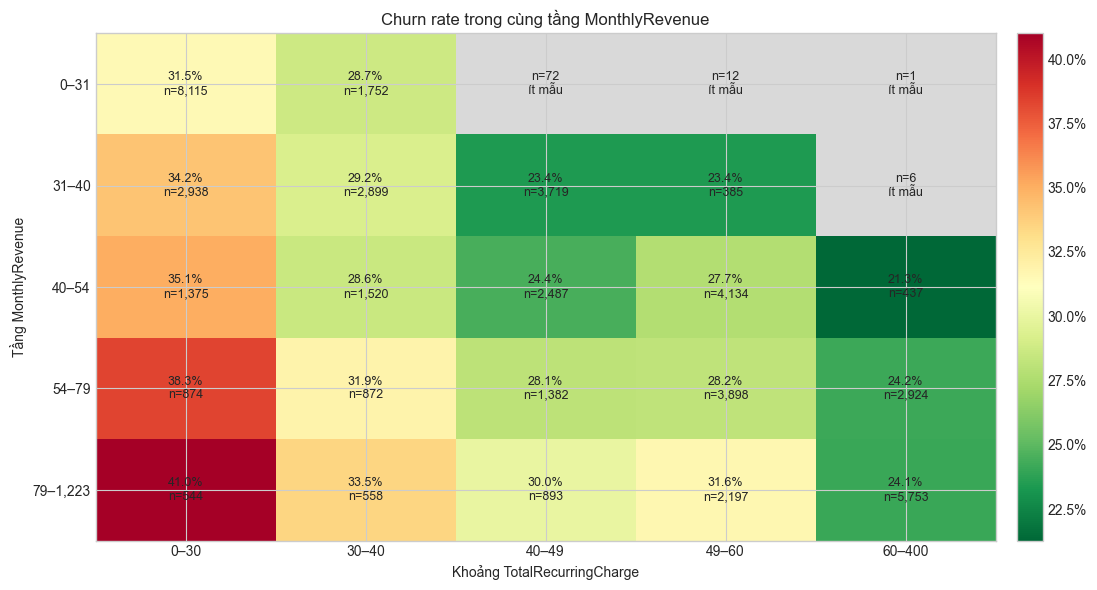

,ValueTier,Candidate_n,Other_n,CandidateChurn,OtherChurn,Difference_pp,Valid
0,0–31,8115,1837,0.3152,0.2961,1.9084,True
1,31–40,2938,7009,0.3417,0.2581,8.3632,True
2,40–54,1375,8578,0.3505,0.2659,8.4633,True
3,54–79,874,9076,0.3833,0.2723,11.1039,True
4,"79–1,223",544,9401,0.4099,0.2699,14.0062,True


In [4]:
charge_order = list(analysis['ChargeBand'].cat.categories)
value_order = list(analysis['ValueTier'].cat.categories)
charge_labels = [interval_label(value) for value in charge_order]
value_labels = [interval_label(value) for value in value_order]

cell_summary = (
    analysis.groupby(['ValueTier', 'ChargeBand'], observed=True)
        .agg(Customers=('Churn_bin', 'size'), Churners=('Churn_bin', 'sum'),
             ChurnRate=('Churn_bin', 'mean'))
        .reset_index()
)
rate_matrix = cell_summary.pivot(index='ValueTier', columns='ChargeBand', values='ChurnRate')
n_matrix = cell_summary.pivot(index='ValueTier', columns='ChargeBand', values='Customers')
rate_matrix = rate_matrix.reindex(index=value_order, columns=charge_order)
n_matrix = n_matrix.reindex(index=value_order, columns=charge_order).fillna(0)
reliable_rate = rate_matrix.where(n_matrix.ge(MIN_CELL_N))

cmap = plt.colormaps['RdYlGn_r'].copy()
cmap.set_bad('#D9D9D9')
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(reliable_rate.to_numpy(dtype=float), cmap=cmap, aspect='auto')
for row in range(len(value_order)):
    for col in range(len(charge_order)):
        n_value = int(n_matrix.iloc[row, col])
        rate_value = rate_matrix.iloc[row, col]
        label = f'{rate_value:.1%}\nn={n_value:,}' if n_value >= MIN_CELL_N else f'n={n_value:,}\nít mẫu'
        ax.text(col, row, label, ha='center', va='center', fontsize=9)
ax.set_xticks(range(len(charge_labels)), charge_labels)
ax.set_yticks(range(len(value_labels)), value_labels)
ax.set_xlabel('Khoảng TotalRecurringCharge')
ax.set_ylabel('Tầng MonthlyRevenue')
ax.set_title('Churn rate trong cùng tầng MonthlyRevenue')
colorbar = fig.colorbar(image, ax=ax, pad=.02)
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

consistency_rows = []
candidate_band_value = candidate['ChargeBand']
for value_tier, group in analysis.groupby('ValueTier', observed=True):
    in_candidate = group['ChargeBand'].eq(candidate_band_value)
    n_candidate = int(in_candidate.sum())
    n_other = int((~in_candidate).sum())
    valid_comparison = n_candidate >= MIN_CELL_N and n_other >= MIN_CELL_N
    candidate_rate = group.loc[in_candidate, 'Churn_bin'].mean()
    other_rate = group.loc[~in_candidate, 'Churn_bin'].mean()
    consistency_rows.append({
        'ValueTier': interval_label(value_tier), 'Candidate_n': n_candidate,
        'Other_n': n_other, 'CandidateChurn': candidate_rate, 'OtherChurn': other_rate,
        'Difference_pp': 100 * (candidate_rate - other_rate), 'Valid': valid_comparison,
    })
value_consistency_table = pd.DataFrame(consistency_rows)
valid_tiers = value_consistency_table.query('Valid')
value_consistency = (valid_tiers['Difference_pp'] > 0).mean() if len(valid_tiers) else np.nan
display(value_consistency_table)


## 4. Kiểm tra điều chỉnh liên tục

Spline logistic được dùng như **guardrail phân tích**, không phải mô hình dự đoán. Nó ước tính đường churn theo phí liên tục sau khi chuẩn hóa trên cùng phân phối `MonthlyRevenue`. Bootstrap tạo khoảng tin cậy cho đường cong và chênh lệch giữa candidate với khoảng có churn thấp nhất.


In [5]:
def fit_adjustment_model(data):
    charge_spline = SplineTransformer(n_knots=N_KNOTS, degree=3, knots='quantile',
                                       include_bias=False, extrapolation='linear')
    revenue_spline = SplineTransformer(n_knots=N_KNOTS, degree=3, knots='quantile',
                                        include_bias=False, extrapolation='linear')
    charge_basis = charge_spline.fit_transform(data[['TotalRecurringCharge']])
    revenue_basis = revenue_spline.fit_transform(data[['MonthlyRevenue']])
    design = np.column_stack([charge_basis, revenue_basis])
    model = LogisticRegression(C=100.0, solver='lbfgs', max_iter=2000, random_state=SEED)
    model.fit(design, data['Churn_bin'].to_numpy())
    return model, charge_spline, revenue_spline

def standardized_curve(model, charge_spline, revenue_spline, charges, revenue_reference):
    revenue_basis = revenue_spline.transform(pd.DataFrame({'MonthlyRevenue': revenue_reference}))
    probabilities = []
    for charge in np.atleast_1d(charges):
        charge_frame = pd.DataFrame({'TotalRecurringCharge': np.full(len(revenue_reference), charge)})
        charge_basis = charge_spline.transform(charge_frame)
        design = np.column_stack([charge_basis, revenue_basis])
        probabilities.append(model.predict_proba(design)[:, 1].mean())
    return np.asarray(probabilities)

reference_revenue = analysis['MonthlyRevenue'].sample(
    n=min(STANDARDIZATION_N, len(analysis)), random_state=SEED).to_numpy()
charge_low, charge_high = analysis['TotalRecurringCharge'].quantile([.01, .99])
charge_grid = np.linspace(charge_low, charge_high, CURVE_POINTS)
candidate_charge = float(candidate['MedianCharge'])
reference_charge = float(reference_band['MedianCharge'])

main_model, main_charge_spline, main_revenue_spline = fit_adjustment_model(analysis)
adjusted_curve = standardized_curve(main_model, main_charge_spline, main_revenue_spline,
                                      charge_grid, reference_revenue)
main_points = standardized_curve(main_model, main_charge_spline, main_revenue_spline,
                                   [candidate_charge, reference_charge], reference_revenue)
adjusted_gap = main_points[0] - main_points[1]

bootstrap_curves, bootstrap_gaps = [], []
for repeat in range(BOOTSTRAP_REPEATS):
    bootstrap_index = rng.integers(0, len(analysis), size=len(analysis))
    sample = analysis.iloc[bootstrap_index].reset_index(drop=True)
    model_b, charge_spline_b, revenue_spline_b = fit_adjustment_model(sample)
    bootstrap_curves.append(standardized_curve(
        model_b, charge_spline_b, revenue_spline_b, charge_grid, reference_revenue))
    points_b = standardized_curve(model_b, charge_spline_b, revenue_spline_b,
                                    [candidate_charge, reference_charge], reference_revenue)
    bootstrap_gaps.append(points_b[0] - points_b[1])

bootstrap_curves = np.vstack(bootstrap_curves)
bootstrap_gaps = np.asarray(bootstrap_gaps)
curve_ci = np.quantile(bootstrap_curves, [.025, .975], axis=0)
adjusted_gap_ci = np.quantile(bootstrap_gaps, [.025, .975])
direction_stability = np.mean(np.sign(bootstrap_gaps) == np.sign(adjusted_gap))


## 5. Quyết định BQ09 bằng risk × reach × adjusted evidence

Candidate chỉ được giữ khi có chênh lệch thực tiễn, đủ độ phủ, còn chiều hướng trong các tầng value và giữ được hiệu ứng sau điều chỉnh liên tục.


In [6]:
raw_excess = float(candidate['ChurnRate'] - overall_churn)
risk_is_meaningful = raw_excess >= MIN_EFFECT
reach_is_sufficient = float(candidate['Reach']) >= MIN_REACH
value_is_consistent = pd.notna(value_consistency) and value_consistency >= MIN_VALUE_CONSISTENCY
adjusted_is_stable = (adjusted_gap >= MIN_EFFECT
                      and adjusted_gap_ci[0] > 0
                      and direction_stability >= MIN_DIRECTION_STABILITY)

if risk_is_meaningful and reach_is_sufficient and value_is_consistent and adjusted_is_stable:
    decision = 'KEEP CANDIDATE — chuyển sang BQ10'
    action = ('Dùng khoảng phí này làm điều kiện sàng lọc phụ cho khách có churn risk cao; '
              'BQ10 phải kiểm tra revenue–charge mismatch trước khi thử bill explanation hoặc right-size plan.')
elif risk_is_meaningful and reach_is_sufficient:
    decision = 'CONTEXT ONLY — có risk/reach nhưng bằng chứng điều chỉnh chưa đủ'
    action = ('Không tạo chiến dịch theo khoảng phí; chỉ dùng làm bối cảnh khi phân tích cùng '
              'MonthlyRevenue, usage và risk score.')
else:
    decision = 'REMOVE — không dùng làm reason code chính sách'
    action = ('Không nhắm mục tiêu theo TotalRecurringCharge; tiếp tục xem biến này như '
              'thông tin mô tả hoặc predictor nếu mô hình chứng minh có ích.')

evidence = pd.DataFrame({
    'Bằng chứng': ['Khoảng phí candidate', 'Số khách', 'Số churner', 'Churn rate',
                   'Chênh lệch so với toàn cohort', 'Reach', 'Churner coverage', 'Lift',
                   'Tỷ lệ tầng value cùng chiều', 'Adjusted gap với khoảng rủi ro thấp',
                   '95% CI adjusted gap', 'Độ ổn định hướng bootstrap'],
    'Kết quả': [candidate['ChargeRange'], f'{int(candidate["Customers"]):,}',
                f'{int(candidate["Churners"]):,}', f'{candidate["ChurnRate"]:.2%}',
                f'{100 * raw_excess:+.2f} pp', f'{candidate["Reach"]:.1%}',
                f'{candidate["ChurnerCoverage"]:.1%}', f'{candidate["Lift"]:.2f}x',
                f'{value_consistency:.1%}' if pd.notna(value_consistency) else 'Không đủ mẫu',
                f'{100 * adjusted_gap:+.2f} pp',
                f'[{100 * adjusted_gap_ci[0]:+.2f}; {100 * adjusted_gap_ci[1]:+.2f}] pp',
                f'{direction_stability:.1%}'],
})
display(evidence)
print(f'QUYẾT ĐỊNH BQ09: {decision}')


,Bằng chứng,Kết quả
0,Khoảng phí candidate,0–30
1,Số khách,"13,846"
2,Số churner,"4,602"
3,Churn rate,33.24%
4,Chênh lệch so với toàn cohort,+4.60 pp
5,Reach,27.8%
6,Churner coverage,32.3%
7,Lift,1.16x
8,Tỷ lệ tầng value cùng chiều,100.0%
9,Adjusted gap với khoảng rủi ro thấp,+12.97 pp


QUYẾT ĐỊNH BQ09: KEEP CANDIDATE — chuyển sang BQ10


## 6. C09 — Biểu đồ kể chuyện chính

Panel trái đặt **risk** và **reach** cạnh nhau. Panel phải là đường churn đã điều chỉnh theo phí liên tục; vùng vàng là candidate mô tả cần được kiểm tra tiếp, không phải ngưỡng áp chính sách ngay.


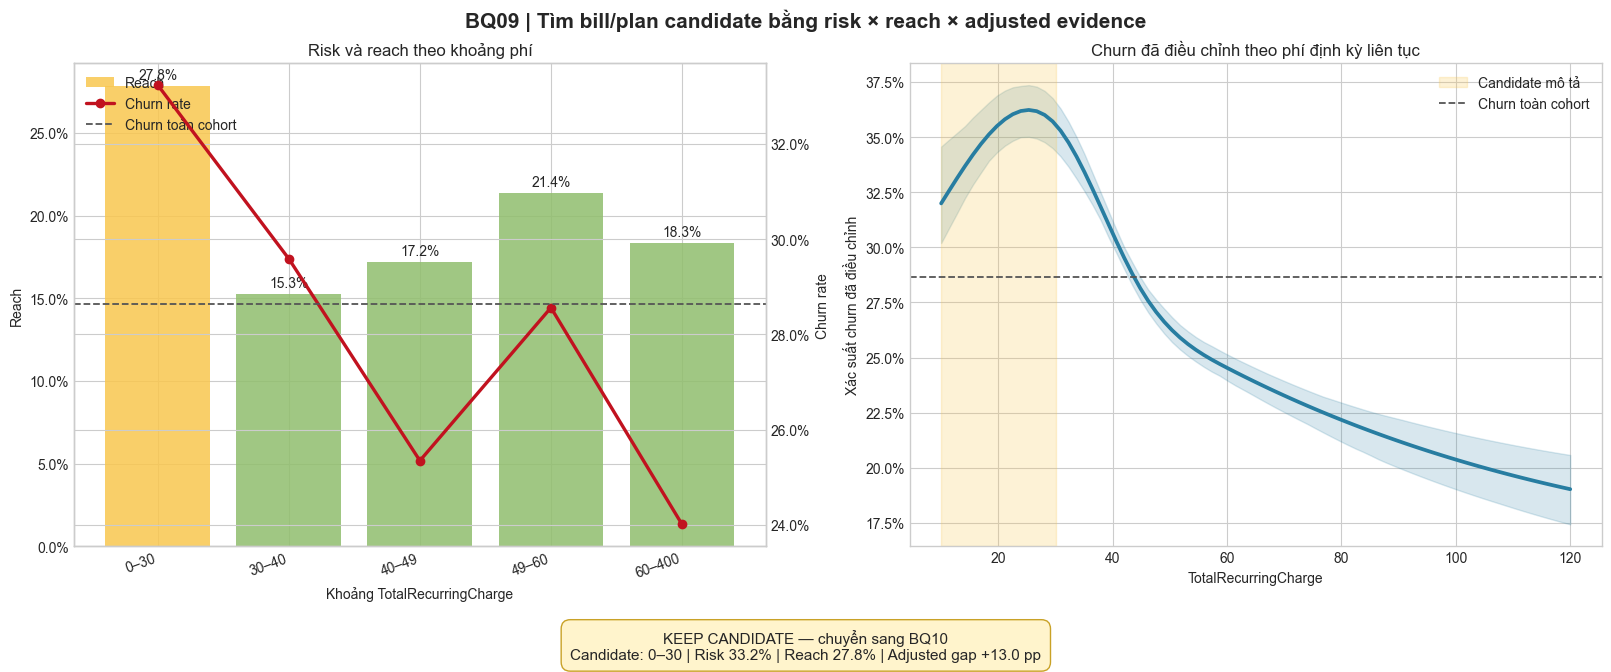

In [7]:
x = np.arange(len(band_summary))
colors = ['#F9C74F' if i == candidate_index else '#90BE6D' for i in band_summary.index]
fig, (ax_risk, ax_curve) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

bars = ax_risk.bar(x, band_summary['Reach'], color=colors, alpha=.85, label='Reach')
ax_risk.set_xticks(x, band_summary['ChargeRange'], rotation=20, ha='right')
ax_risk.set_xlabel('Khoảng TotalRecurringCharge')
ax_risk.set_ylabel('Reach')
ax_risk.yaxis.set_major_formatter(PercentFormatter(1))
ax_risk.bar_label(bars, labels=[f'{value:.1%}' for value in band_summary['Reach']], padding=3)
risk_axis = ax_risk.twinx()
risk_axis.plot(x, band_summary['ChurnRate'], color='#C1121F', marker='o', linewidth=2.4,
               label='Churn rate')
risk_axis.axhline(overall_churn, color='#555555', linestyle='--', linewidth=1.3,
                  label='Churn toàn cohort')
risk_axis.set_ylabel('Churn rate')
risk_axis.yaxis.set_major_formatter(PercentFormatter(1))
ax_risk.set_title('Risk và reach theo khoảng phí')
handles_1, labels_1 = ax_risk.get_legend_handles_labels()
handles_2, labels_2 = risk_axis.get_legend_handles_labels()
ax_risk.legend(handles_1 + handles_2, labels_1 + labels_2, loc='upper left')

ax_curve.plot(charge_grid, adjusted_curve, color='#277DA1', linewidth=2.7)
ax_curve.fill_between(charge_grid, curve_ci[0], curve_ci[1], color='#277DA1', alpha=.18)
candidate_interval = candidate['ChargeBand']
ax_curve.axvspan(max(charge_grid.min(), candidate_interval.left),
                 min(charge_grid.max(), candidate_interval.right),
                 color='#F9C74F', alpha=.23, label='Candidate mô tả')
ax_curve.axhline(overall_churn, color='#555555', linestyle='--', linewidth=1.3,
                 label='Churn toàn cohort')
ax_curve.set(title='Churn đã điều chỉnh theo phí định kỳ liên tục',
             xlabel='TotalRecurringCharge', ylabel='Xác suất churn đã điều chỉnh')
ax_curve.yaxis.set_major_formatter(PercentFormatter(1))
ax_curve.legend()

fig.suptitle('BQ09 | Tìm bill/plan candidate bằng risk × reach × adjusted evidence',
             fontsize=15, fontweight='bold')
decision_box = (f'{decision}\nCandidate: {candidate["ChargeRange"]} | '
                f'Risk {candidate["ChurnRate"]:.1%} | Reach {candidate["Reach"]:.1%} | '
                f'Adjusted gap {100 * adjusted_gap:+.1f} pp')
fig.text(0.5, -0.04, decision_box, ha='center', va='top', fontsize=11,
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#FFF4CC', edgecolor='#C9A227'))
plt.show()


## 7. Insight tự động để đưa vào báo cáo


In [8]:
story = f'''
### Insight BQ09

Trong cohort hợp lệ, khoảng `TotalRecurringCharge` **{candidate['ChargeRange']}** có churn rate cao nhất ở mức 
**{candidate['ChurnRate']:.1%}**, cao hơn toàn cohort **{100 * raw_excess:+.1f} điểm phần trăm**. 
Khoảng này bao phủ **{candidate['Reach']:.1%} khách hàng** ({int(candidate['Customers']):,} người) 
và chứa **{candidate['ChurnerCoverage']:.1%} tổng churner** ({int(candidate['Churners']):,} người).

Sau khi chuẩn hóa `MonthlyRevenue`, chênh lệch churn giữa mức phí đại diện của candidate và khoảng 
rủi ro thấp nhất là **{100 * adjusted_gap:+.1f} điểm phần trăm**, với 95% CI từ 
**{100 * adjusted_gap_ci[0]:+.1f} đến {100 * adjusted_gap_ci[1]:+.1f} điểm phần trăm**.

**Quyết định:** {decision}.  
**Hành động:** {action}

Kết quả không chứng minh phí gây churn và không phải lý do giảm giá đại trà. BQ10 phải kiểm tra thêm 
mismatch giữa revenue, recurring charge và mức sử dụng trước khi xác định reason code hoặc treatment.
'''
display(Markdown(story))



### Insight BQ09

Trong cohort hợp lệ, khoảng `TotalRecurringCharge` **0–30** có churn rate cao nhất ở mức 
**33.2%**, cao hơn toàn cohort **+4.6 điểm phần trăm**. 
Khoảng này bao phủ **27.8% khách hàng** (13,846 người) 
và chứa **32.3% tổng churner** (4,602 người).

Sau khi chuẩn hóa `MonthlyRevenue`, chênh lệch churn giữa mức phí đại diện của candidate và khoảng 
rủi ro thấp nhất là **+13.0 điểm phần trăm**, với 95% CI từ 
**+11.2 đến +14.4 điểm phần trăm**.

**Quyết định:** KEEP CANDIDATE — chuyển sang BQ10.  
**Hành động:** Dùng khoảng phí này làm điều kiện sàng lọc phụ cho khách có churn risk cao; BQ10 phải kiểm tra revenue–charge mismatch trước khi thử bill explanation hoặc right-size plan.

Kết quả không chứng minh phí gây churn và không phải lý do giảm giá đại trà. BQ10 phải kiểm tra thêm 
mismatch giữa revenue, recurring charge và mức sử dụng trước khi xác định reason code hoặc treatment.


## Nối BQ09 vào storytelling chung

1. **BQ08** xác định `MonthlyRevenue` như value proxy, không coi revenue cao là nguyên nhân churn.
2. **BQ09** tìm vùng phí có risk và reach đáng chú ý, rồi kiểm tra tín hiệu khi value tương đương.
3. **BQ10** quyết định vùng này có thật sự là price/plan mismatch candidate hay chỉ là cấu trúc dữ liệu.
4. Chỉ khách có risk cao và reason code phù hợp mới được đưa vào thử nghiệm bill explanation/right-size plan.
